### **SELECTED CANDIDATES**
- Blend model w0.65 (CatPop + ItemCF_no_colour)
- Cat-Pop (baseline)

Metrics: HIT@12 - Reach, catalog coverage, head_share
* Test user: Have history, at least one new-article purchase in the test window
* Hit: An article the user never owned and bought
* Items: Owned items excluded (exclude_seen=True)

Expected phenomenon:
* Apply the same new-item definition to every model, including the baseline.
* Report the blend’s accuracy cost together with reach and head_share. The CI on the HIT lift alone won’t show its benefit -> tradeoff

In [11]:
import pandas as pd
import numpy as np
from utils.load_splits import load_splits
from utils.eval_tools import compare_models, bootstrap_compare, plot_comparison, plot_bootstrap, plot_tradeoff

from models.cat_pop import CategoryPopularityModel
from models.itemCFv2 import ItemCFModel
from models.blend_user_discovery import BlendModel

In [2]:
# data
train_val_raw, test_raw=load_splits(
    train_path="../data/split/train.parquet",
    val_path="../data/split/val.parquet",
    test_path="../data/split/test.parquet",
    concat_train_val=True
)

train_val = train_val_raw[train_val_raw['sales_channel_id']==2]
test = test_raw[test_raw['sales_channel_id']==2]
assert train_val.t_dat.max() < test.t_dat.min()

articles=pd.read_parquet("../data/cleaned_art.parquet")
types = articles.set_index("article_id")["product_type_no"] #product type
pc = articles.set_index("article_id")["product_code"] #product code

In [6]:
comps={
    "cf_lastday_nocolour": ItemCFModel(types, allow_same_category=True, source="last_day",exclude_owned_product_code=True, article_product=pc),
    "cat_pop": CategoryPopularityModel(types),
}

models={
    **comps,
    "blend_w0.65": BlendModel(comps, weights={"cat_pop": 0.65, "cf_lastday_nocolour": 1 - 0.65}, rrf_c=10, fit_components=False, k=12),
}

In [7]:
summary, per_user=compare_models(models, train_val, test, baseline="cat_pop",k=12, problem="discovery")

Setup: user_group=warm, truth_mode=novel -> 6,846 users, 26,144 relevant purchases
        20.9% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating cf_lastday_nocolour ...
Evaluating cat_pop ...
Evaluating blend_w0.65 ...


In [8]:
ci_df, paired_df=bootstrap_compare(per_user, baseline="cat_pop", k=12)

In [9]:
# freeze results
summary.to_csv("frozen_results/discovery/test_summary.csv")
ci_df.to_csv("frozen_results/discovery/ci_df_test.csv")
paired_df.to_csv("frozen_results/discovery/paired_df_test.csv")

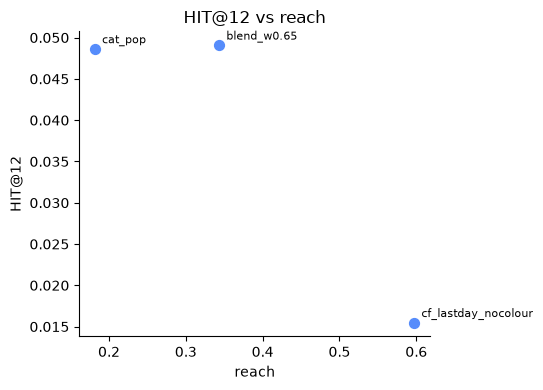

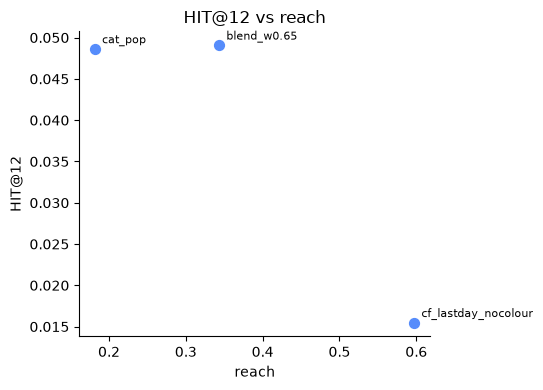

In [13]:
plot_tradeoff(summary, x="reach", save_path=f"figures/discovery/tradeoff.png")

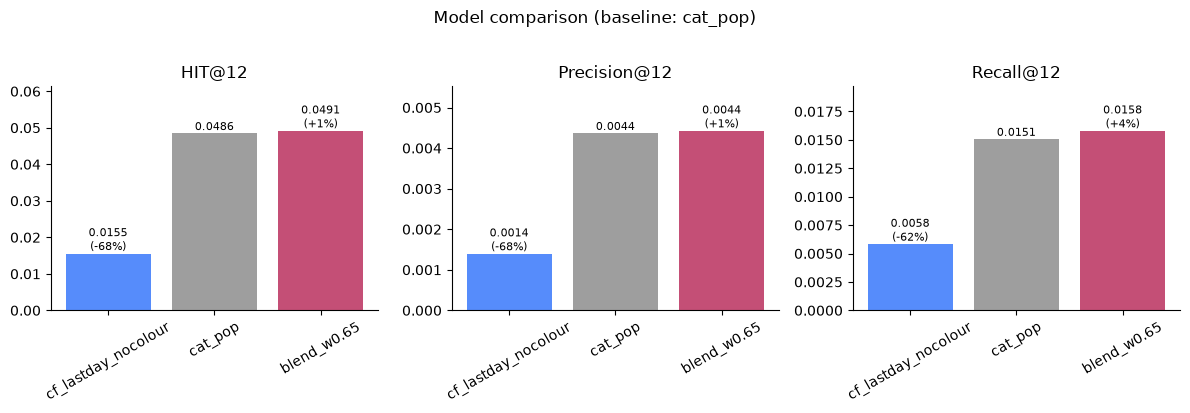

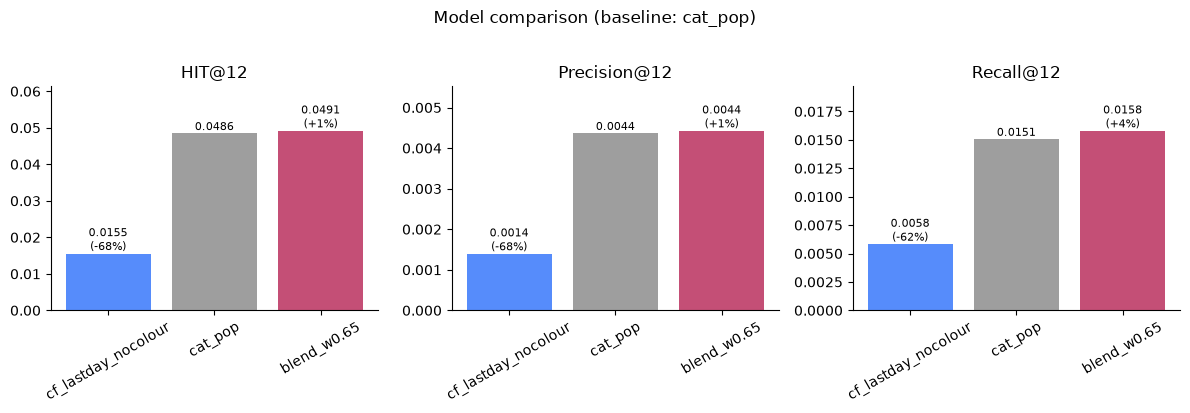

In [14]:
plot_comparison(summary, baseline="cat_pop", k=12, save_path=f"figures/discovery/test_summary.png")

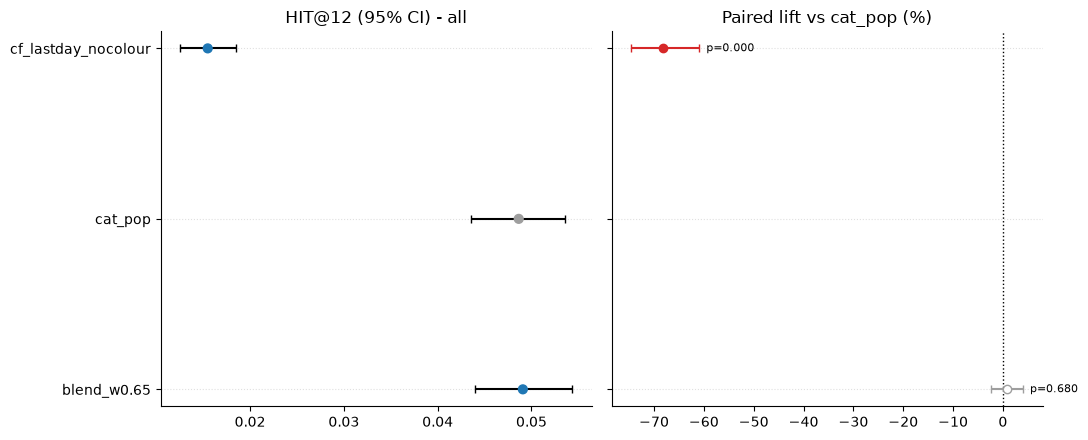

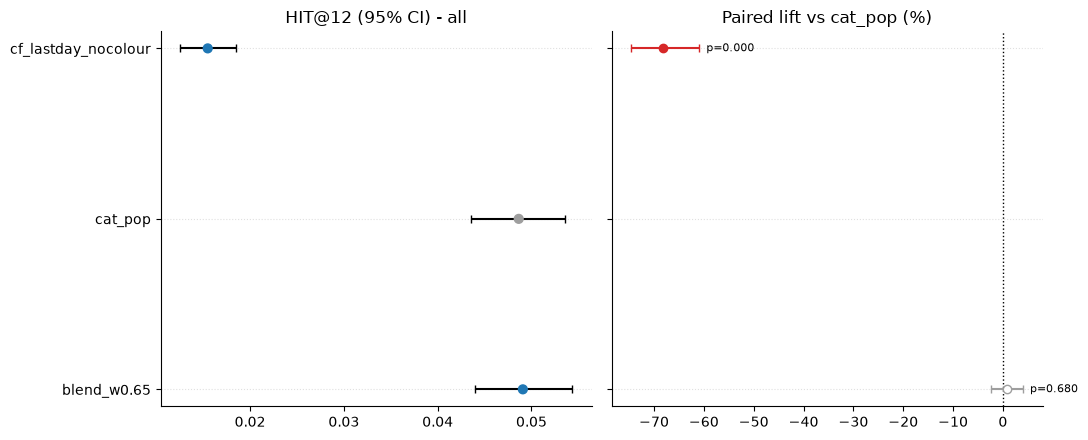

In [15]:
#only HIT@12
plot_bootstrap(ci_df, paired_df, baseline="cat_pop", save_path=f"figures/discovery/test_bootstrap.png")

### **CONCLUSION**
* Accuracy: blend_w0.65 is statistically indistinguishable from cat_pop on all three metrics, with point estimates slightly above it. Say “comparable”. The CIs allow a small loss (about 2–3%) as well as a small gain
* Discovery: from the plot, reach is about 0.34 for the blend against about 0.18 for cat_pop, close to 2× at the same HIT. That is the benefit, and nothing was given up for it. CF alone reaches about 0.60 but loses about 68% of the HIT.
* Validation agreement: the blend’s HIT lift on validation (about −1.5% at w0.65) and now (+0.9%) both sit within noise around 0. That consistency is the point.
* Reach, coverage and head_share have no CIs, since they are plain catalog-level numbers -> limitations